In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned_retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [2]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

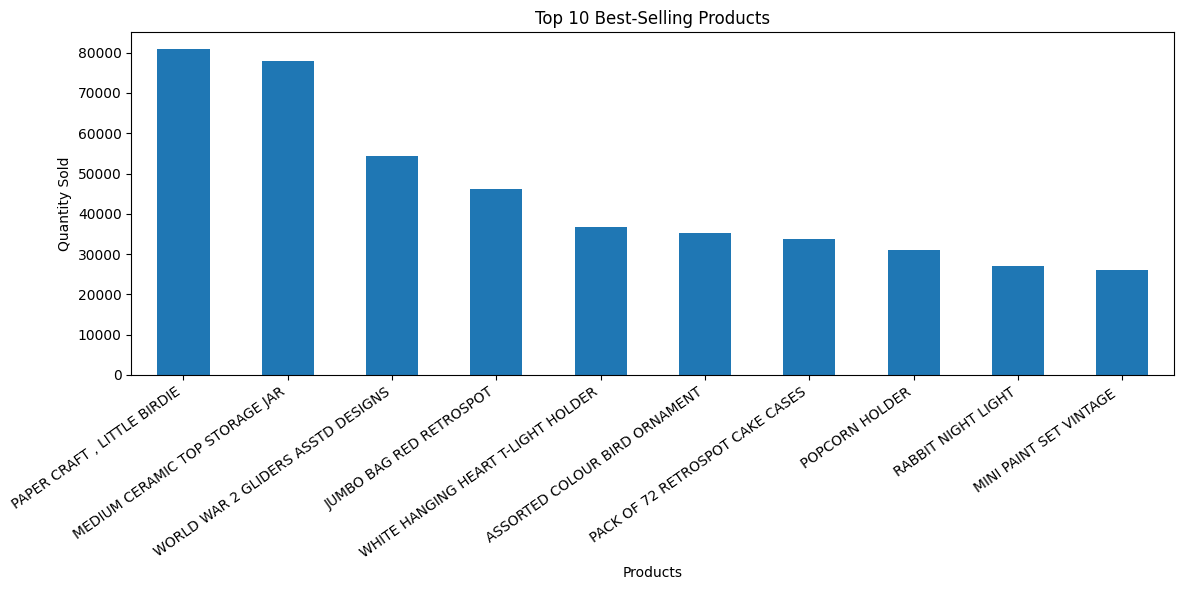

In [3]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

top_products.plot(kind='bar')

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Products")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=35, ha='right')

plt.tight_layout()

plt.show()

## Business Insight: Top Products

- A small number of products generate a large share of sales.
- Decorative and gift-related products appear among the most purchased items.
- This suggests customers strongly prefer home decoration products.
  

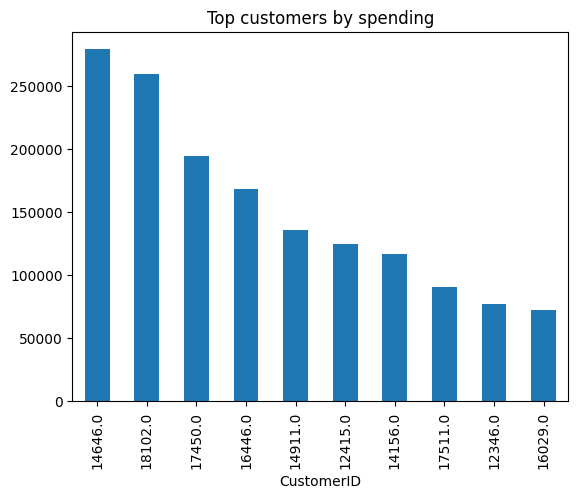

In [4]:
top_customers = (
    df.groupby('CustomerID')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers.plot(kind='bar')
plt.title("Top customers by spending")
plt.show()

## Business Insight: Customer Behavior

- Revenue is concentrated among a small group of customers.
- Some customers purchase significantly more than average.
- These customers could be targeted for loyalty programs.

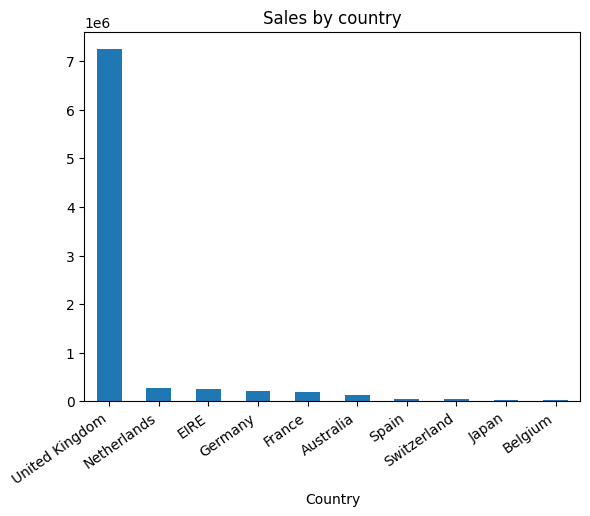

In [5]:
country_sales = (
    df.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales.plot(kind='bar')
plt.title("Sales by country")
plt.xticks(rotation=35, ha='right')
plt.show()

## Business Insight: Geographic Sales

- Sales are concentrated in a few countries.
- The United Kingdom dominates revenue.
- International expansion opportunities may exist.

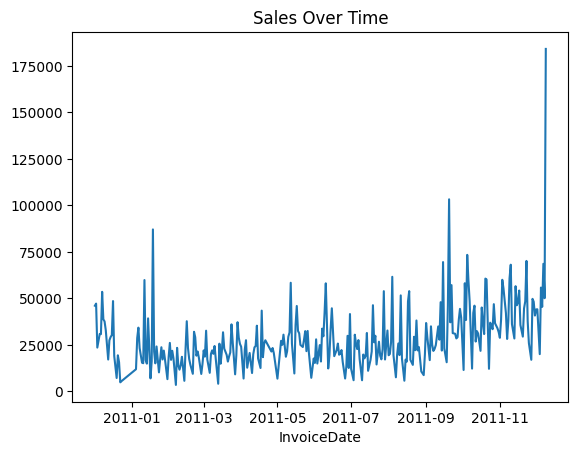

In [6]:
daily_sales = df.groupby(
    df['InvoiceDate'].dt.date
)['TotalPrice'].sum()

daily_sales.plot()
plt.title("Sales Over Time")
plt.show()

## Business Insight: Sales Trends

- Sales fluctuate over time.
- Some peaks may indicate seasonal demand.
- Promotions could be aligned with high-demand periods.

# Key Findings

1. Best-selling products drive a large portion of sales.
2. Customer spending is highly uneven.
3. Revenue is dominated by specific countries.
4. Sales show temporal patterns.

These insights can support inventory planning, marketing strategy, and personalized recommendations.